# 2. Exponential growth (and decay)

**Model:** $N(t) = N_0\, e^{r t} = N_0\, b^{t}$, with $b = e^{r}$

- $N_0$ is the starting value.
- $r$ is the continuous growth rate ($r>0$ growth, $r<0$ decay). The **relative** growth rate is constant.
- Equal time steps give equal **ratios** (constant factor $b$), not equal additions.
- Doubling time: $T_d = \dfrac{\ln 2}{r}$. Half-life for decay: $T_{1/2} = \dfrac{\ln 2}{|r|}$.
- Taking logs linearises the model: $\ln N = \ln N_0 + r\,t$.

**Why it matters.** The exponential model is the most studied in the learning literature (Confrey & Smith, 1995; Castillo-Garsow, 2013). People also tend to underestimate it (Timmers & Wagenaar, 1977), and the bias is reported to be much smaller when the problem is framed with doubling times (Schonger & Sele, 2021). This notebook lets you see both effects with simulated data.

All data here is **simulated**; the true parameters are known.

**Contents**
1. The model and its parameters
2. The signature: constant ratios
3. Simulated example A: bacteria (two ways to fit)
4. Simulated example B: linear intuition vs the exponential truth
5. Simulated example C: drug concentration (decay, half-life)
6. Simulation: how noise affects the estimated doubling time
7. Compound interest as an exponential
8. Using your own data
9. Exercises

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
rng = np.random.default_rng(2026)

## 1. The model and its parameters

Left: ordinary axes. Right: the same curves with a **logarithmic** y-axis, where every exponential becomes a straight line whose slope is $r$.

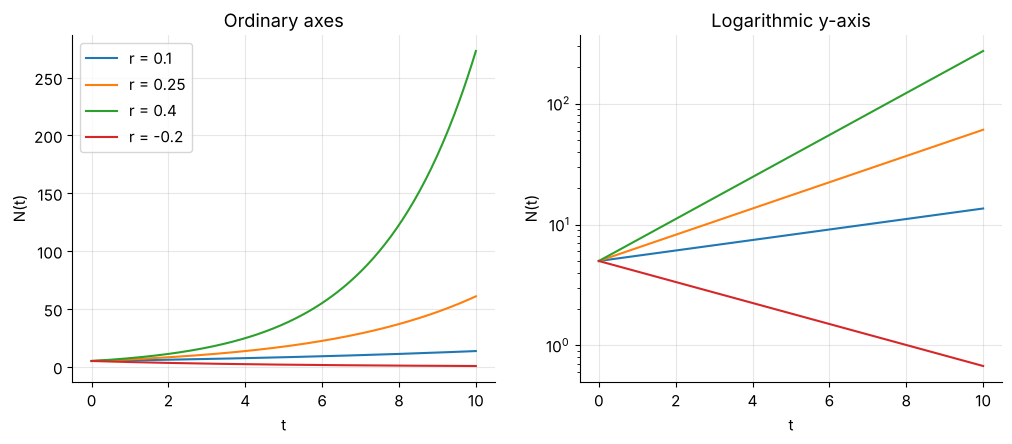

In [2]:
def exponential(t, n0, r):
    return n0 * np.exp(r * t)

t = np.linspace(0, 10, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for r in [0.1, 0.25, 0.4, -0.2]:
    for ax in axes:
        ax.plot(t, exponential(t, 5, r), label=f"r = {r}")
axes[0].set_title("Ordinary axes")
axes[1].set_title("Logarithmic y-axis")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("t")
    ax.set_ylabel("N(t)")
axes[0].legend()
plt.show()

## 2. The signature: constant ratios

For an exponential every step multiplies by the same factor $b = e^{r}$. The **differences** keep growing; the **ratios** stay constant. Compare with the linear notebook, where it is the other way round.

In [3]:
t_int = np.arange(0, 8)
n_int = exponential(t_int, 5, np.log(2))        # doubling every step: b = 2
print("t        :", t_int)
print("N        :", n_int)
print("ΔN       :", np.round(np.diff(n_int), 2), " <- differences keep growing")
print("N(t+1)/N :", np.round(n_int[1:] / n_int[:-1], 3), " <- constant ratio")

t        : [0 1 2 3 4 5 6 7]
N        : [  5.  10.  20.  40.  80. 160. 320. 640.]
ΔN       : [  5.  10.  20.  40.  80. 160. 320.]  <- differences keep growing
N(t+1)/N : [2. 2. 2. 2. 2. 2. 2.]  <- constant ratio


## 3. Simulated example A: bacteria

A culture starts with 500 cells and doubles every 40 minutes, so the true rate is $r = \ln 2 / 40$ per minute. We count every 20 minutes for 5 hours. Counting error is **multiplicative** (about 8%), as is typical for counts.

We fit in two ways and compare:
- **Nonlinear fit** of $N_0 e^{rt}$ directly.
- **Log-linear fit**: regress $\ln N$ on $t$, a straight-line fit.

In [4]:
true_n0, true_doubling = 500.0, 40.0
true_r = np.log(2) / true_doubling
minutes = np.arange(0, 301, 20)
counts = exponential(minutes, true_n0, true_r) * np.exp(rng.normal(0, 0.08, minutes.size))

# (a) nonlinear least squares
popt, pcov = curve_fit(exponential, minutes, counts, p0=[counts[0], 0.01])
n0_nl, r_nl = popt

# (b) log-linear regression
lin = stats.linregress(minutes, np.log(counts))
n0_ll, r_ll = np.exp(lin.intercept), lin.slope

print(f"True        : N0 = {true_n0:7.1f}, r = {true_r:.5f}, doubling time = {true_doubling:.1f} min")
print(f"Nonlinear   : N0 = {n0_nl:7.1f}, r = {r_nl:.5f}, doubling time = {np.log(2) / r_nl:.1f} min")
print(f"Log-linear  : N0 = {n0_ll:7.1f}, r = {r_ll:.5f}, doubling time = {np.log(2) / r_ll:.1f} min")

True        : N0 =   500.0, r = 0.01733, doubling time = 40.0 min
Nonlinear   : N0 =   597.8, r = 0.01662, doubling time = 41.7 min
Log-linear  : N0 =   493.2, r = 0.01740, doubling time = 39.8 min


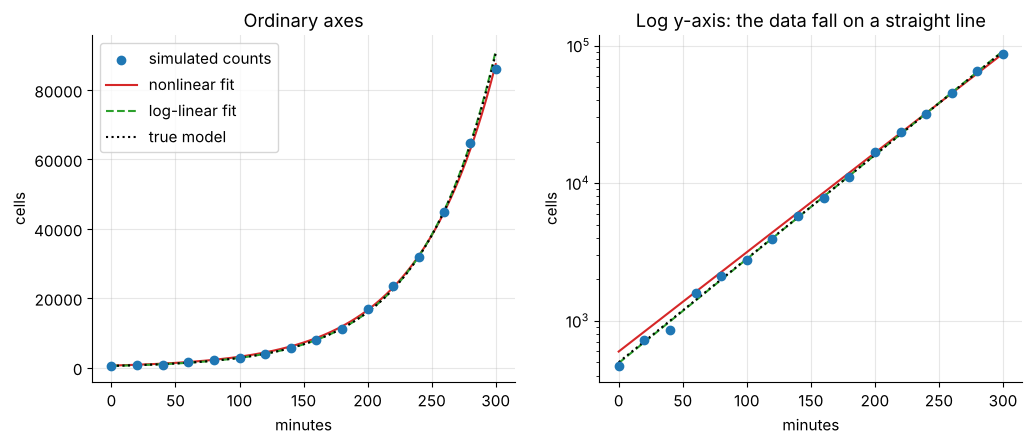

In [5]:
t_fine = np.linspace(0, 300, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax in axes:
    ax.scatter(minutes, counts, color="tab:blue", label="simulated counts", zorder=3)
    ax.plot(t_fine, exponential(t_fine, n0_nl, r_nl), color="tab:red", label="nonlinear fit")
    ax.plot(t_fine, exponential(t_fine, n0_ll, r_ll), color="tab:green", ls="--", label="log-linear fit")
    ax.plot(t_fine, exponential(t_fine, true_n0, true_r), "k:", label="true model")
    ax.set_xlabel("minutes")
    ax.set_ylabel("cells")
axes[0].set_title("Ordinary axes")
axes[1].set_title("Log y-axis: the data fall on a straight line")
axes[1].set_yscale("log")
axes[0].legend()
plt.show()

Compare the estimates with the true values. Because the noise here is **multiplicative** (a percentage of each count), the log-linear fit is usually the more accurate: it treats every point equally on the log scale. The nonlinear fit implicitly assumes a constant *additive* error, so it is dominated by the largest counts at the right-hand end. With a log y-axis the exponential becomes a straight line, which is why logarithms are the natural tool for analysing exponential data (see the logarithmic notebook).

Which fit is closer depends on the particular random draw, so try a few seeds (change `2026` in the first code cell).

## 4. Simulated example B: linear intuition versus the exponential truth

A common error is to extrapolate with a straight line. Here we only observe the first 2 hours (7 points), fit a **line**, and predict the count at 5 hours. Then we compare with the exponential truth.

True count at 300 min               :      90510
Linear extrapolation from first 2 h :       8468  ( 9.4% of truth)
Exponential extrapolation, same data:      98858  (109.2% of truth)


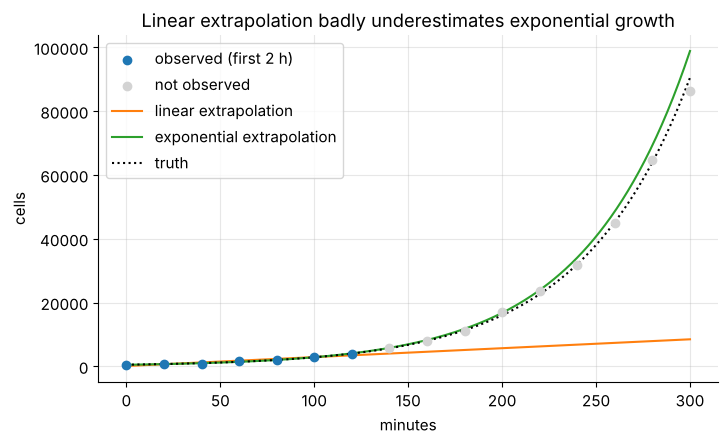

In [6]:
early = minutes <= 120
line = stats.linregress(minutes[early], counts[early])
pred_linear_300 = line.intercept + line.slope * 300
truth_300 = exponential(300, true_n0, true_r)

# same early data, but fitted with the exponential model
lin_early = stats.linregress(minutes[early], np.log(counts[early]))
pred_exp_300 = np.exp(lin_early.intercept + lin_early.slope * 300)

print(f"True count at 300 min               : {truth_300:10.0f}")
print(f"Linear extrapolation from first 2 h : {pred_linear_300:10.0f}  ({pred_linear_300 / truth_300:5.1%} of truth)")
print(f"Exponential extrapolation, same data: {pred_exp_300:10.0f}  ({pred_exp_300 / truth_300:5.1%} of truth)")

fig, ax = plt.subplots()
ax.scatter(minutes[early], counts[early], color="tab:blue", label="observed (first 2 h)", zorder=3)
ax.scatter(minutes[~early], counts[~early], color="lightgray", label="not observed", zorder=3)
ax.plot(t_fine, line.intercept + line.slope * t_fine, color="tab:orange", label="linear extrapolation")
ax.plot(t_fine, np.exp(lin_early.intercept + lin_early.slope * t_fine), color="tab:green", label="exponential extrapolation")
ax.plot(t_fine, exponential(t_fine, true_n0, true_r), "k:", label="truth")
ax.set_xlabel("minutes")
ax.set_ylabel("cells")
ax.set_title("Linear extrapolation badly underestimates exponential growth")
ax.legend()
plt.show()

**Framing matters.** The same information can be stated as a growth *rate* ("grows by about 1.7% per minute") or as a *doubling time* ("doubles every 40 minutes"). Schonger & Sele (2021) report that bias is much smaller with doubling times. Try both wordings with your students and compare their predictions.

In [7]:
print(f"Growth per minute: {np.expm1(true_r):.2%}")
print(f"Doubling time    : {true_doubling:.0f} minutes")
print(f"Doublings in 300 min: {300 / true_doubling:.1f}  ->  factor 2^{300 / true_doubling:.1f} = {2 ** (300 / true_doubling):.0f}")

Growth per minute: 1.75%
Doubling time    : 40 minutes
Doublings in 300 min: 7.5  ->  factor 2^7.5 = 181


## 5. Simulated example C: drug concentration (exponential decay)

A drug has a half-life of 6 hours, so $r = -\ln 2 / 6$. The starting concentration is 80 mg/L and measurement error is additive (±2 mg/L). We estimate the half-life and the time at which the concentration drops below a threshold of 5 mg/L.

Estimated half-life: 5.97 h (true 6.0)
Time to fall below 5.0 mg/L: 23.8 h (true 24.0 h)


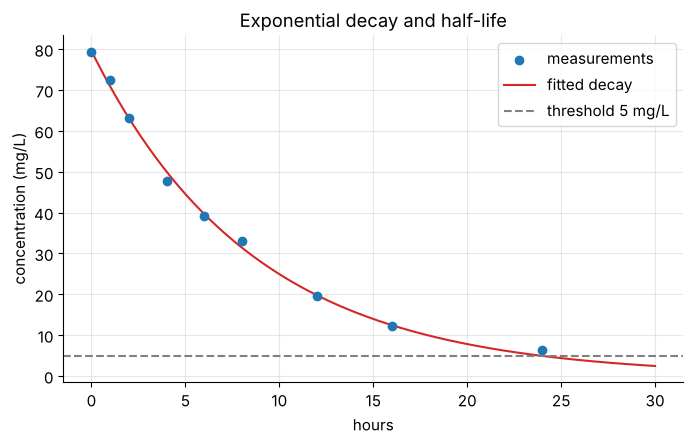

In [8]:
c0, half_life = 80.0, 6.0
true_r_decay = -np.log(2) / half_life
hours = np.array([0, 1, 2, 4, 6, 8, 12, 16, 24], dtype=float)
conc = exponential(hours, c0, true_r_decay) + rng.normal(0, 2.0, hours.size)

popt_d, _ = curve_fit(exponential, hours, conc, p0=[conc[0], -0.1])
c0_hat, r_hat = popt_d
half_hat = np.log(2) / abs(r_hat)
threshold = 5.0
t_thr_hat = np.log(threshold / c0_hat) / r_hat
t_thr_true = np.log(threshold / c0) / true_r_decay

print(f"Estimated half-life: {half_hat:.2f} h (true {half_life})")
print(f"Time to fall below {threshold} mg/L: {t_thr_hat:.1f} h (true {t_thr_true:.1f} h)")

t_fine_h = np.linspace(0, 30, 300)
fig, ax = plt.subplots()
ax.scatter(hours, conc, label="measurements", zorder=3)
ax.plot(t_fine_h, exponential(t_fine_h, c0_hat, r_hat), color="tab:red", label="fitted decay")
ax.axhline(threshold, color="gray", ls="--", label="threshold 5 mg/L")
ax.set_xlabel("hours")
ax.set_ylabel("concentration (mg/L)")
ax.set_title("Exponential decay and half-life")
ax.legend()
plt.show()

## 6. Simulation: how noise affects the estimated doubling time

We repeat the bacteria experiment 500 times at four noise levels and use the log-linear regression each time. The true doubling time is 40 minutes.

noise   2%: mean doubling time =  40.0 min, sd = 0.13 min
noise   5%: mean doubling time =  40.0 min, sd = 0.30 min
noise  10%: mean doubling time =  40.0 min, sd = 0.61 min
noise  20%: mean doubling time =  40.0 min, sd = 1.24 min


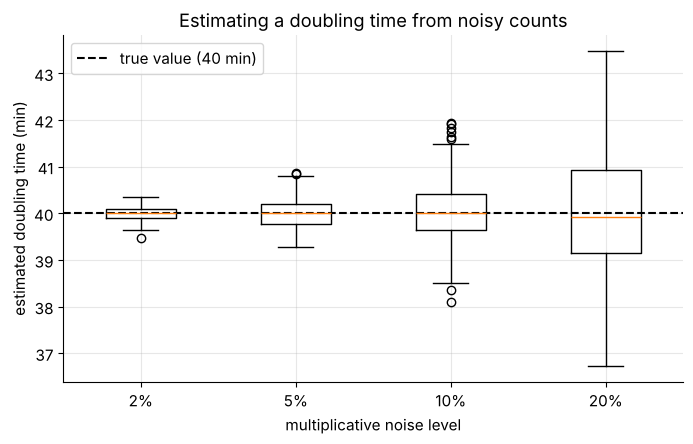

In [9]:
def estimate_doubling(noise_sd):
    y = exponential(minutes, true_n0, true_r) * np.exp(rng.normal(0, noise_sd, minutes.size))
    slope = stats.linregress(minutes, np.log(y)).slope
    return np.log(2) / slope

noise_levels = [0.02, 0.05, 0.10, 0.20]
estimates = {sd: np.array([estimate_doubling(sd) for _ in range(500)]) for sd in noise_levels}

for sd, est in estimates.items():
    print(f"noise {sd:>4.0%}: mean doubling time = {est.mean():5.1f} min, sd = {est.std(ddof=1):4.2f} min")

fig, ax = plt.subplots()
ax.boxplot(list(estimates.values()), tick_labels=[f"{sd:.0%}" for sd in noise_levels])
ax.axhline(true_doubling, color="k", ls="--", label="true value (40 min)")
ax.set_xlabel("multiplicative noise level")
ax.set_ylabel("estimated doubling time (min)")
ax.set_title("Estimating a doubling time from noisy counts")
ax.legend()
plt.show()

## 7. Compound interest as an exponential

Compound interest is a standard Grade 11 context: with annual rate $i$, $A(n) = P (1 + i)^n = P\, e^{n \ln(1+i)}$, so $b = 1 + i$ and $r = \ln(1+i)$.

After 30 years: compound = €3,243, simple = €2,200
Continuous rate r = ln(1+i) = 0.03922


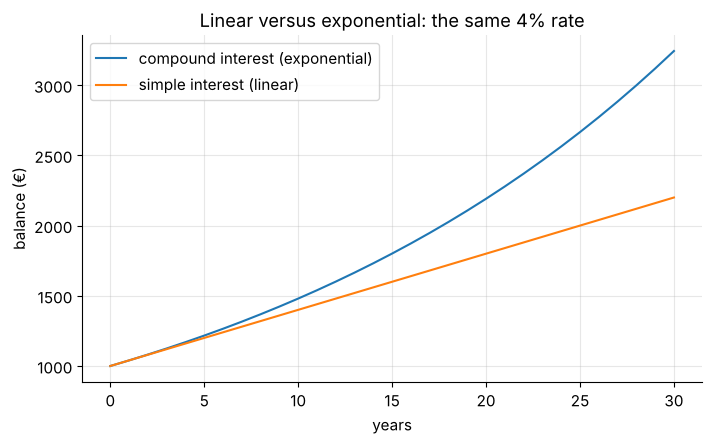

In [10]:
P, i = 1000.0, 0.04
years = np.arange(0, 31)
compound = P * (1 + i) ** years
simple = P * (1 + i * years)                # linear: simple interest

print(f"After 30 years: compound = €{compound[-1]:,.0f}, simple = €{simple[-1]:,.0f}")
print(f"Continuous rate r = ln(1+i) = {np.log(1 + i):.5f}")

fig, ax = plt.subplots()
ax.plot(years, compound, label="compound interest (exponential)")
ax.plot(years, simple, label="simple interest (linear)")
ax.set_xlabel("years")
ax.set_ylabel("balance (€)")
ax.set_title("Linear versus exponential: the same 4% rate")
ax.legend()
plt.show()

## 8. Using your own data

In [11]:
# import pandas as pd
# df = pd.read_csv("my_data.csv")                       # columns: t, y (y > 0)
# fit_own = stats.linregress(df["t"], np.log(df["y"]))  # log-linear fit
# r_own, n0_own = fit_own.slope, np.exp(fit_own.intercept)
# print("r =", r_own, " N0 =", n0_own, " doubling time =", np.log(2) / r_own)

## 9. Exercises

1. In section 3 change the doubling time to 25 minutes. How does the log-linear fitted line change on the log axis?
2. In section 4, observe only the first 60 minutes. How much worse does the linear extrapolation get?
3. In section 6 replace multiplicative noise by additive noise (`y = exponential(...) + rng.normal(0, 30, size)`). Does the log-linear regression still work? What goes wrong when values are near zero?
4. Show algebraically that $b = e^{r}$ and that the doubling time is $\ln 2 / r$.